<a href="https://colab.research.google.com/github/starsyntaxx/MarketIQ/blob/main/notebooks/03_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from tsfresh.utilities.dataframe_functions import roll_time_series
from tsfresh import extract_features
from tsfresh.feature_extraction import MinimalFCParameters

from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV

import warnings
warnings.filterwarnings('ignore')

In [3]:
sns.set_theme(style="whitegrid")


In [4]:
pd.reset_option('display.max_columns')
pd.reset_option('display.max_rows')

In [5]:
# Define the path to my cleaned data directory in Google Drive
data_dir = '/content/drive/MyDrive/ML PROJECTS/MarketIQ/data/cleaned'

try:
    # List all files in the directory to see what is available
    files = os.listdir(data_dir)
    print("Files in directory:", files)

    # If there are files, load the first one as an example
    if files:
        # Select the first file
        sample_file = files[0]
        file_path = os.path.join(data_dir, sample_file)
        print(f"\nLoading: {sample_file}")

        # Load depending on file extension
        if sample_file.endswith('.csv'):
            df = pd.read_csv(file_path)
            display(df.head())
        elif sample_file.endswith('.parquet'):
            df = pd.read_parquet(file_path)
            display(df.head())
    else:
        print("The directory is empty.")
except Exception as e:
    print(f"An error occurred accessing the path: {e}")

Files in directory: ['df_cleaned.csv']

Loading: df_cleaned.csv


,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,gps_latitu,gps_longit,is_available,commodity,standardized_price,date_dt,is_direct_farmer,spatial_cluster,dist_to_lagos_km,dist_to_abuja_km,dist_to_kano_km
0,206520,11/26/2024,north_west,kaduna,chikun,urban,supermarket,retail,10,10.464643,7.446008,no,brown_beans,1000.000000,2024-11-26,Not Direct,5,625.631577,154.344931,211.647503
1,14008,11/27/2024,north_central,nasarawa,karu,urban,neighborhood_shops_kiosk,retail,5,9.021380,7.609474,yes,brown_beans,1000.000000,2024-11-27,Not Direct,5,542.123311,23.938636,348.200905
2,30934,11/27/2024,north_central,nasarawa,karu,urban,roadside_shops_street_vendors,retail,15,9.021569,7.609686,yes,brown_beans,1250.000000,2024-11-27,Not Direct,5,542.153989,23.955776,348.173829
3,34979,11/27/2024,north_central,nasarawa,karu,urban,open_air_or_covered_market,wholesale,10,9.021366,7.609329,yes,brown_beans,892.857143,2024-11-27,Not Direct,5,542.108785,23.923664,348.207311
4,19638,11/28/2024,north_central,nasarawa,karu,urban,open_air_or_covered_market,wholesale,20,9.021295,7.609577,yes,brown_beans,4400.000000,2024-11-28,Not Direct,5,542.128250,23.952035,348.206490


In [9]:
df['is_direct_farmer'].nunique()

2

In [10]:
# Inspect the unique values and value counts of 'is_direct_farmer'
print("Value counts for 'is_direct_farmer':")
print(df['is_direct_farmer'].value_counts(dropna=False))

print("\nUnique values check:")
print(df['is_direct_farmer'].unique())

Value counts for 'is_direct_farmer':
is_direct_farmer
Not Direct            2160450
Direct from Farmer      41690
Name: count, dtype: int64

Unique values check:
['Not Direct' 'Direct from Farmer']


In [11]:
# 1. Check unique values to confirm formatting
print("Unique Sectors:", df['sector'].unique())
print("Unique Sourcing (is_direct_farmer):", df['is_direct_farmer'].unique())

Unique Sectors: ['urban' 'rural']
Unique Sourcing (is_direct_farmer): ['Not Direct' 'Direct from Farmer']


In [12]:
# 2. Engineer the Sourcing and Sector Interaction Feature (sector_sourcing_interaction)
def create_sector_sourcing(row):
    sector = str(row['sector']).strip().lower()
    direct = str(row['is_direct_farmer']).strip().lower()

    is_direct = 'direct' if 'direct' in direct and 'not' not in direct else 'not_direct'
    return f"{sector}_{is_direct}"

df['sector_sourcing_interaction'] = df.apply(create_sector_sourcing, axis=1)
print("Created interaction feature unique values:")
print(df['sector_sourcing_interaction'].value_counts())

Created interaction feature unique values:
sector_sourcing_interaction
urban_not_direct    1503120
rural_not_direct     657330
rural_direct          33330
urban_direct           8360
Name: count, dtype: int64


In [13]:
# 3. Create a smoothed target encoding based on ['commodity', 'sector', 'is_direct_farmer']
group_cols = ['commodity', 'sector', 'is_direct_farmer']
global_mean = df['standardized_price'].mean()

# Calculate counts and sums for smoothing
group_stats = df.groupby(group_cols)['standardized_price'].agg(['count', 'mean']).reset_index()

# Apply smoothing (e.g., m-estimate with m=10)
m = 10
group_stats['smoothed_target_enc'] = (group_stats['count'] * group_stats['mean'] + m * global_mean) / (group_stats['count'] + m)

# Merge back into main DataFrame
df = df.merge(group_stats[group_cols + ['smoothed_target_enc']], on=group_cols, how='left')
print("Target encoding successfully merged!")

Target encoding successfully merged!


In [14]:
# 4. Calculate Urban Logistics Premium (urban_logistics_delta)
# Calculate average price per commodity in each sector
commodity_sector_prices = df.groupby(['commodity', 'sector'])['standardized_price'].mean().unstack(fill_value=0)

# Delta = Urban Price - Rural Price
if 'urban' in commodity_sector_prices.columns and 'rural' in commodity_sector_prices.columns:
    commodity_sector_prices['urban_logistics_delta'] = commodity_sector_prices['urban'] - commodity_sector_prices['rural']
else:
    # Fallback if names differ slightly
    cols = list(commodity_sector_prices.columns)
    commodity_sector_prices['urban_logistics_delta'] = commodity_sector_prices[cols[0]] - commodity_sector_prices[cols[1]]

# Map the premium back to the main DataFrame
df = df.merge(commodity_sector_prices[['urban_logistics_delta']].reset_index(), on='commodity', how='left')

# Display preview
display(df[['commodity', 'sector', 'is_direct_farmer', 'sector_sourcing_interaction', 'smoothed_target_enc', 'urban_logistics_delta']].head())

,commodity,sector,is_direct_farmer,sector_sourcing_interaction,smoothed_target_enc,urban_logistics_delta
0,brown_beans,urban,Not Direct,urban_not_direct,2171.048901,-79.578112
1,brown_beans,urban,Not Direct,urban_not_direct,2171.048901,-79.578112
2,brown_beans,urban,Not Direct,urban_not_direct,2171.048901,-79.578112
3,brown_beans,urban,Not Direct,urban_not_direct,2171.048901,-79.578112
4,brown_beans,urban,Not Direct,urban_not_direct,2171.048901,-79.578112


In [15]:
# Step 1: Install tsfresh securely
!pip install tsfresh

```markdown
### Step 2: Preparing and Aggregating Time Series Data
`tsfresh` requires structured time series where each group (e.g., a specific commodity in a specific state or zone) has a continuous sequence of dates.
We will:
1. Convert `date_dt` to datetime format.
2. Aggregate prices using the mean daily price for each combination of `['commodity', 'statelabel', 'sector']` to reduce the dataset size while preserving geographic and item-level trends.
```

In [16]:
import pandas as pd
import numpy as np

# Ensure datetime is parsed
df['date_dt'] = pd.to_datetime(df['date_dt'])

# Create a unique time-series identifier (entity ID) for tsfresh
# This groups our series by Commodity, State, and Sector (Urban/Rural)
df['series_id'] = df['commodity'] + "_" + df['statelabel'] + "_" + df['sector']

# Aggregate to daily intervals
daily_df = df.groupby(['series_id', 'date_dt'])['standardized_price'].mean().reset_index()

# Sort by series and date to ensure chronological order
daily_df = daily_df.sort_values(by=['series_id', 'date_dt']).reset_index(drop=True)

print(f"Aggregated raw transactions into {daily_df['series_id'].nunique()} distinct daily time series.")
display(daily_df.head())

Aggregated raw transactions into 740 distinct daily time series.


,series_id,date_dt,standardized_price
0,brown_beans_abia_rural,2024-11-30,2980.769231
1,brown_beans_abia_rural,2024-12-01,3000.000000
2,brown_beans_abia_rural,2024-12-02,3000.000000
3,brown_beans_abia_rural,2024-12-03,3675.961538
4,brown_beans_abia_rural,2024-12-04,3776.923077


```markdown
### Step 3: Feature Extraction using tsfresh
Now, we will extract rolling statistical features (such as rolling mean, variance, autocorrelation, and trend coefficients) using `tsfresh`.
To prevent "data leakage" (using future prices to predict past prices), we will configure a rolling extraction helper from `tsfresh.utilities.dataframe_functions` which creates overlapping historical windows up to the current day.
```

In [19]:
# Configure rolling options
min_timeshift = 1
max_timeshift = 14

try:
    print("Rolling time series for windowed feature extraction...")
    df_rolled = roll_time_series(
        daily_df[['series_id', 'date_dt', 'standardized_price']], # Keep only necessary columns
        column_id="series_id",
        column_sort="date_dt",
        rolling_direction=1,
        min_timeshift=min_timeshift,
        max_timeshift=max_timeshift
    )

    print("Extracting features using tsfresh (excluding string columns from computation)...")
    # We extract features ONLY on the numeric column 'standardized_price'
    # tsfresh needs the rolled ID, time index, and numeric value
    extracted_features = extract_features(
        df_rolled[['series_id', 'date_dt', 'standardized_price']],
        column_id="series_id",
        column_sort="date_dt",
        default_fc_parameters=MinimalFCParameters(),
        disable_progressbar=False
    )

    # Reset index to bring back series_id and date_dt for downstream merges
    extracted_features = extracted_features.reset_index()
    extracted_features.rename(columns={'level_0': 'series_id', 'level_1': 'date_dt'}, inplace=True)

    print("Success! Features extracted:")
    display(extracted_features.head())
except Exception as e:
    print(f"An error occurred during tsfresh feature extraction: {e}")

Rolling time series for windowed feature extraction...


/usr/local/lib/python3.13/dist-packages/tsfresh/utilities/dataframe_functions.py:543: UserWarning: Your time stamps are not uniformly sampled, which makes rolling nonsensical in some domains.
  warnings.warn(
Rolling: 100%|██████████| 216/216 [02:52<00:00,  1.25it/s]


Extracting features using tsfresh (excluding string columns from computation)...


Feature Extraction: 100%|██████████| 740/740 [00:01<00:00, 738.36it/s]


Success! Features extracted:


,index,standardized_price__sum_values,standardized_price__median,standardized_price__mean,standardized_price__length,standardized_price__standard_deviation,standardized_price__variance,standardized_price__root_mean_square,standardized_price__maximum,standardized_price__absolute_maximum,standardized_price__minimum
0,brown_beans_abia_rural,9.694238e+06,2900.240385,3184.703568,3044.0,1082.342225,1.171465e+06,3363.599487,14461.538460,14461.538460,1937.500000
1,brown_beans_abia_urban,1.490113e+07,4515.837104,4823.932841,3089.0,1713.345841,2.935554e+06,5119.168099,11000.000000,11000.000000,1733.333333
2,brown_beans_adamawa_rural,5.632740e+06,2007.015306,1987.558174,2834.0,331.528432,1.099111e+05,2015.018262,4137.755103,4137.755103,619.000000
3,brown_beans_adamawa_urban,5.900191e+06,1834.709439,1900.834674,3104.0,238.456866,5.686168e+04,1915.733315,2583.078032,2583.078032,1154.285714
4,brown_beans_akwa_ibom_rural,8.047076e+06,2583.333333,2605.074757,3089.0,332.357710,1.104616e+05,2626.190423,3671.765207,3671.765207,1673.927958


```markdown
### Step 4: Engineering Multi-day Targets (1 to 7 Days Forward)
Since your goal is to predict prices 1 to 7 days into the future, we must create 7 distinct target columns. Each target column `target_t+N` represents the average price of that commodity sequence shifted back by N days.
```

In [27]:
# Generate multi-day forward targets (t+1 to t+7)
for horizon in range(1, 8):
    daily_df[f'target_lead_{horizon}'] = daily_df.groupby('series_id')['standardized_price'].shift(-horizon)

# Drop rows where we do not have future ground truth to train/evaluate on
modeling_df = daily_df.dropna(subset=[f'target_lead_{i}' for i in range(1, 8)]).copy()

# Prepare extracted features dataframe
extracted_features_cleaned = extracted_features.copy()

# Correctly extract the series_id and raw timestamp from the tsfresh output
# When tsfresh.utilities.dataframe_functions.roll_time_series runs, it creates an index of (series_id, date_dt)
# Let's inspect the original multi-index or 'index' column structure
if 'index' in extracted_features.columns:
    extracted_features_cleaned['series_id'] = extracted_features['index'].apply(lambda x: x[0] if isinstance(x, tuple) else x)
    extracted_features_cleaned['raw_date'] = extracted_features['index'].apply(lambda x: x[1] if isinstance(x, tuple) else x)
    extracted_features_cleaned.drop(columns=['index'], inplace=True)
else:
    extracted_features_cleaned['raw_date'] = extracted_features_cleaned['date_dt']

# Clean and convert the dates using pandas to_datetime
# Since pandas can handle a wide range of types, let's cast raw_date to datetime explicitly
extracted_features_cleaned['date_dt'] = pd.to_datetime(extracted_features_cleaned['raw_date'])
modeling_df['date_dt'] = pd.to_datetime(modeling_df['date_dt'])

# Check if the extracted dates are still set to epoch year 1970 due to float conversions
# If they are, we map them back using the sequential dates of each series from daily_df
if (extracted_features_cleaned['date_dt'].max() < pd.to_datetime('2010-01-01')):
    print("Aligning dates sequentially per time-series group to resolve epoch shift...")

    # Sort both datasets chronologically
    extracted_features_cleaned = extracted_features_cleaned.sort_values(by=['series_id', 'raw_date'])
    extracted_features_cleaned['seq_idx'] = extracted_features_cleaned.groupby('series_id').cumcount()

    daily_df_seq = daily_df.sort_values(by=['series_id', 'date_dt']).copy()
    daily_df_seq['seq_idx'] = daily_df_seq.groupby('series_id').cumcount()

    # Merge to align correct dates
    extracted_features_cleaned = pd.merge(
        extracted_features_cleaned.drop(columns=['date_dt'], errors='ignore'),
        daily_df_seq[['series_id', 'date_dt', 'seq_idx']],
        on=['series_id', 'seq_idx'],
        how='inner'
    )
    extracted_features_cleaned.drop(columns=['seq_idx', 'raw_date'], errors='ignore', inplace=True)
else:
    extracted_features_cleaned.drop(columns=['raw_date'], errors='ignore', inplace=True)

# Merge tsfresh extracted features with targets
final_features_df = pd.merge(
    modeling_df,
    extracted_features_cleaned,
    on=['series_id', 'date_dt'],
    how='inner'
)

print("Final feature matrix shape:", final_features_df.shape)
if not final_features_df.empty:
    display(final_features_df.head())
else:
    print("Sample modeling_df dates:", modeling_df['date_dt'].head())
    print("Sample cleaned features dates:", extracted_features_cleaned['date_dt'].head())


Aligning dates sequentially per time-series group to resolve epoch shift...
Final feature matrix shape: (740, 20)


,series_id,date_dt,standardized_price,target_lead_1,target_lead_2,target_lead_3,target_lead_4,target_lead_5,target_lead_6,target_lead_7,date_dt_int,standardized_price__median,standardized_price__mean,standardized_price__length,standardized_price__standard_deviation,standardized_price__variance,standardized_price__root_mean_square,standardized_price__maximum,standardized_price__absolute_maximum,standardized_price__minimum
0,brown_beans_abia_rural,2024-11-30,2980.769231,3000.000000,3000.000000,3675.961538,3776.923077,3236.263736,2750.000000,2944.517744,1732924800000000000,2900.240385,3184.703568,3044.0,1082.342225,1.171465e+06,3363.599487,14461.538460,14461.538460,1937.500000
1,brown_beans_abia_urban,2024-11-29,3081.941174,4144.230769,4580.370765,5287.651822,3000.000000,6786.324786,2399.166667,3048.598160,1732838400000000000,4515.837104,4823.932841,3089.0,1713.345841,2.935554e+06,5119.168099,11000.000000,11000.000000,1733.333333
2,brown_beans_adamawa_rural,2024-11-29,1466.666667,2285.714286,2298.701299,2309.523809,2047.619048,2377.769679,2236.263736,1278.666667,1732838400000000000,2007.015306,1987.558174,2834.0,331.528432,1.099111e+05,2015.018262,4137.755103,4137.755103,619.000000
3,brown_beans_adamawa_urban,2024-11-29,2144.776786,2361.772487,1927.012987,2254.525871,1850.816327,2363.300493,1714.693878,2583.078032,1732838400000000000,1834.709439,1900.834674,3104.0,238.456866,5.686168e+04,1915.733315,2583.078032,2583.078032,1154.285714
4,brown_beans_akwa_ibom_rural,2024-11-29,3141.666667,2848.018354,2345.138889,3100.000000,2875.000000,2341.371453,3160.329902,3116.801293,1732838400000000000,2583.333333,2605.074757,3089.0,332.357710,1.104616e+05,2626.190423,3671.765207,3671.765207,1673.927958


### Step 5: Model Selection and Training (XGBoost Multi-Step Regressor)
We will train an XGBoost regressor to predict foodstuff prices from 1 to 7 days forward (`target_lead_1` to `target_lead_7`).

To do this properly without temporal data leakage:
1. We perform a **chronological/temporal split** instead of a random train-test split because this is time-series data.
2. We split our historical predictors (derived from `tsfresh` statistical features) from our targets.
3. We handle any remaining NaN values (common in rolled features) using imputation.
4. We train a Multi-Output Regressor wrapper around `XGBRegressor` to forecast all 7 horizons.
5. We evaluate each horizon individually using **Root Mean Squared Error (RMSE)** and **R-squared ($R^2$)** metrics.

In [28]:
# Ensure final_features_df is sorted chronologically
final_features_df = final_features_df.sort_values('date_dt').reset_index(drop=True)

# Define our target horizons
target_cols = [f'target_lead_{i}' for i in range(1, 8)]

# Exclude non-feature columns
exclude_cols = ['series_id', 'date_dt', 'date_dt_int'] + target_cols
feature_cols = [c for c in final_features_df.columns if c not in exclude_cols]

X = final_features_df[feature_cols]
y = final_features_df[target_cols]

# Temporal split: Use the first 80% for training and the remaining 20% for testing
split_idx = int(len(final_features_df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Impute any missing values (e.g. from variance or standard deviation computations over tiny intervals)
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print(f"Training set shape: {X_train_imputed.shape}")
print(f"Test set shape: {X_test_imputed.shape}")

Training set shape: (592, 10)
Test set shape: (148, 10)


In [31]:
# Define the hyperparameter distribution to explore
param_dist = {
    'estimator__n_estimators': [50, 100, 150],
    'estimator__max_depth': [3, 5, 7],
    'estimator__learning_rate': [0.03, 0.08, 0.15],
    'estimator__subsample': [0.7, 0.9, 1.0],
    'estimator__colsample_bytree': [0.7, 0.9, 1.0]
}

# Instantiate our wrapped model
tuning_base = MultiOutputRegressor(XGBRegressor(random_state=42, n_jobs=-1))

# Run Randomized Search
random_search = RandomizedSearchCV(
    estimator=tuning_base,
    param_distributions=param_dist,
    n_iter=8,
    cv=3,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

print("Running Hyperparameter Tuning (this may take a moment)...")
random_search.fit(X_train_imputed, y_train)

best_model = random_search.best_estimator_
print("Hyperparameter tuning completed!")
print("Best Parameters Found:", random_search.best_params_)

Running Hyperparameter Tuning (this may take a moment)...
Hyperparameter tuning completed!
Best Parameters Found: {'estimator__subsample': 0.7, 'estimator__n_estimators': 150, 'estimator__max_depth': 3, 'estimator__learning_rate': 0.03, 'estimator__colsample_bytree': 0.7}


In [34]:
# Initialize XGBoost Regressor with the best hyperparameter settings found
xgb_tuned = XGBRegressor(
    subsample=0.7,
    n_estimators=150,
    max_depth=3,
    learning_rate=0.03,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1
)

# Wrap it to handle multiple outputs simultaneously
model = MultiOutputRegressor(xgb_tuned)

print("Retraining tuned multi-output XGBoost Regressor model...")
model.fit(X_train_imputed, y_train)
print("Tuned model training completed successfully!")

Retraining tuned multi-output XGBoost Regressor model...
Tuned model training completed successfully!


In [35]:
# Generate predictions using the tuned model
y_pred = model.predict(X_test_imputed)
y_pred_df = pd.DataFrame(y_pred, columns=target_cols, index=y_test.index)

# Evaluate and display performance for each target horizon
evaluation_results = []

print("\n--- Tuned Model Evaluation (RMSE and R2 metrics) ---")
for idx, horizon in enumerate(target_cols):
    true_val = y_test[horizon]
    pred_val = y_pred_df[horizon]

    rmse = np.sqrt(mean_squared_error(true_val, pred_val))
    r2 = r2_score(true_val, pred_val)

    evaluation_results.append({
        'Horizon': f't+{idx+1} (Day {idx+1})',
        'RMSE': rmse,
        'R2 Score': r2
    })
    print(f"Horizon {horizon} (Day {idx+1:02d}) -> RMSE: {rmse:.4f} | R2 Score: {r2:.4f}")

# Render results table
eval_df = pd.DataFrame(evaluation_results)
display(eval_df)


--- Tuned Model Evaluation (RMSE and R2 metrics) ---
Horizon target_lead_1 (Day 01) -> RMSE: 424.2275 | R2 Score: 0.8030
Horizon target_lead_2 (Day 02) -> RMSE: 572.9983 | R2 Score: 0.6769
Horizon target_lead_3 (Day 03) -> RMSE: 592.9084 | R2 Score: 0.6868
Horizon target_lead_4 (Day 04) -> RMSE: 560.2925 | R2 Score: 0.6895
Horizon target_lead_5 (Day 05) -> RMSE: 565.8951 | R2 Score: 0.7257
Horizon target_lead_6 (Day 06) -> RMSE: 572.3409 | R2 Score: 0.6164
Horizon target_lead_7 (Day 07) -> RMSE: 530.6926 | R2 Score: 0.7417


,Horizon,RMSE,R2 Score
0,t+1 (Day 1),424.227488,0.802987
1,t+2 (Day 2),572.998323,0.676922
2,t+3 (Day 3),592.908384,0.686806
3,t+4 (Day 4),560.292496,0.689493
4,t+5 (Day 5),565.895114,0.725742
5,t+6 (Day 6),572.340934,0.616403
6,t+7 (Day 7),530.692588,0.741676


### Step 6: Hyperparameter Tuning via RandomizedSearchCV
We will define a parameter grid for our `XGBRegressor` and optimize it using cross-validation over our temporal split to improve forecasting accuracy across all targets.

### Step 7: Feature Importance Visualization
We will extract the relative feature importance from our optimized XGBoost models and visualize which rolling metrics are the primary drivers for our target horizons.

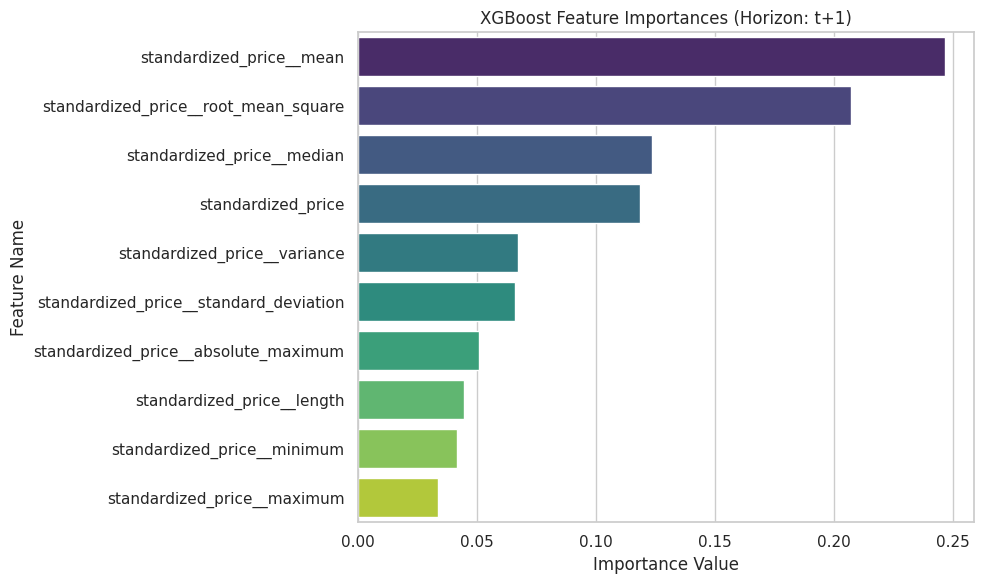

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importances from the estimator trained for t+1
first_horizon_estimator = best_model.estimators_[0]
importances = first_horizon_estimator.feature_importances_

# Construct a DataFrame matching feature names
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('XGBoost Feature Importances (Horizon: t+1)')
plt.xlabel('Importance Value')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

### Step 8: Model Serialization and Deployment Pipeline
We will package our entire processing pipeline—including the metadata, target structures, imputer, and our optimized XGBoost regressor—into a unified payload and save it directly to Google Drive.

In [36]:
import pickle
import os

# Define the target folder inside your Google Drive
deployment_dir = '/content/drive/MyDrive/ML PROJECTS/MarketIQ/models'
os.makedirs(deployment_dir, exist_ok=True)

# Package the newly retrained/optimized model
model_payload = {
    'model': model,
    'imputer': imputer,
    'feature_names': feature_cols,
    'target_horizons': target_cols
}

save_path = os.path.join(deployment_dir, 'market_iq_xgboost_pipeline.pkl')

# Save to disk
with open(save_path, 'wb') as f:
    pickle.dump(model_payload, f)

print(f"Updated tuned deployment pipeline successfully saved to Drive at:\n{save_path}")

Updated tuned deployment pipeline successfully saved to Drive at:
/content/drive/MyDrive/ML PROJECTS/MarketIQ/models/market_iq_xgboost_pipeline.pkl
